# NLE internals

`00_nle_frontend.ipynb` does all of this in four calls: `load_config`,
`train`, `load_model`, `sample_posterior`. This notebook does the same job
with those four calls taken apart, so you can see what each one is actually
doing and change any step of it.

Read this once. After that, use `00` unless you are changing something the
API does not expose.

The last cell maps every step back onto the API call that replaces it.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import pytorch_lightning as pl

REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

from nle_dsph import datasets
from nle_dsph.nle import NLE, build_flow
from nle_dsph.transforms import (
    RandomProjection, StarBatch, UncertaintySampler,
    build_transformation, compute_field_norm,
)

torch.set_num_threads(8)

data_root = '/home/jupyter-tvnguyen/scratch/sbi_dsph/training_datasets'
data_name = '8p_ZhaoPlumCOM_v4'

labels = ('dm_alpha', 'dm_beta', 'dm_gamma', 'dm_log_rdm', 'dm_log_rho0',
          'df_beta0', 'df_log_ra')
cond_labels = ('stellar_log_rstar_kpc',)

## 1. The raw simulation

One shard. `pos` and `vel` are full 3-D phase space in the galaxy frame:
kpc and km/s, no projection, no noise, no selection.

That is not what you observe, which is the whole point of the next section.

In [2]:
node_feats, graph_feats = datasets.read_datasets(
    data_root, data_name, num_datasets=1)

# take a subset so this notebook runs in a couple of minutes
num_galaxies = 2000
n_rows = int(graph_feats['num_stars'][:num_galaxies].sum())
node_feats = {k: v[:n_rows] for k, v in node_feats.items()}
graph_feats = {k: v[:num_galaxies] for k, v in graph_feats.items()}

print(f'{num_galaxies} galaxies, {n_rows:,} stars')
print('pos[0] =', np.round(node_feats['pos'][0], 4), 'kpc')
print('vel[0] =', np.round(node_feats['vel'][0], 2), 'km/s')

100%|██████████| 1/1 [00:00<00:00,  3.88it/s]

2000 galaxies, 196,673 stars
pos[0] = [-0.7589 -0.4056  0.7096] kpc
vel[0] = [-18.37  23.19   6.93] km/s


## 2. From simulation to observation

`StarBatch` is the container everything passes around. It holds physical,
unnormalised fields:

| field | what it is |
|---|---|
| `pos` | `(B, 3)` raw Cartesian, or `(B, 2)` sky plane after projection |
| `vel` | `(B, 3)` raw, or `(B, k)` after projection |
| `vel_error` | `(B, k)` per-star measurement sigma. `None` until set |
| `theta` | `(B, n_params)` the galaxy's inferred parameters, per star |
| `cond` | `(B, n_cond)` the measured conditioning, per star |

Two transforms turn a simulation into an observation.

`RandomProjection` draws a line of sight and projects onto it. You lose one
velocity component to the line of sight and one position component entirely.

`UncertaintySampler` draws a per-star sigma, adds Gaussian noise to the
velocity, and records the sigma in `vel_error` so the flow can condition on
it.

**NOTE**: a new projection and a new noise draw happen on *every batch of
every epoch*. This is augmentation, not preprocessing. It is what teaches
the flow that the likelihood depends on `sigma_v`, and it is why one set of
simulations can stand in for many observations.

In [3]:
# one galaxy, raw
start, end = graph_feats['ptr'][0], graph_feats['ptr'][1]
raw = StarBatch(
    pos=torch.tensor(node_feats['pos'][start:end], dtype=torch.float32),
    vel=torch.tensor(node_feats['vel'][start:end], dtype=torch.float32))

torch.manual_seed(0)
projected = RandomProjection(use_proper_motions=False)(raw)
noised = UncertaintySampler(
    distribution_type='jeffreys_varied', vel_idx=0,
    low_range=(0.01, 0.1), width_range=(5.0, 30.0))(projected)

print('raw      ', 'pos', tuple(raw.pos.shape), 'vel', tuple(raw.vel.shape),
      'vel_error', raw.vel_error)
print('projected', 'pos', tuple(projected.pos.shape),
      'vel', tuple(projected.vel.shape), 'vel_error', projected.vel_error)
print('noised   ', 'pos', tuple(noised.pos.shape),
      'vel', tuple(noised.vel.shape),
      'vel_error', tuple(noised.vel_error.shape))

print(f'\nsigma_v drawn for this galaxy: '
      f'{noised.vel_error[:, 0].min():.2f} - '
      f'{noised.vel_error[:, 0].max():.2f} km/s')
print('v_los before noise:', np.round(projected.vel[:3, 0].numpy(), 2))
print('v_los after noise :', np.round(noised.vel[:3, 0].numpy(), 2))

raw       pos (97, 3) vel (97, 3) vel_error None
projected pos (97, 2) vel (97, 1) vel_error None
noised    pos (97, 2) vel (97, 1) vel_error (97, 1)

sigma_v drawn for this galaxy: 0.05 - 20.49 km/s
v_los before noise: [ 10.39  12.7  -38.53]
v_los after noise : [ 10.57  12.24 -38.6 ]


In practice you build both at once with `build_transformation`, which is what
the config's `pre_transforms` block describes. Same thing, one object.

In [4]:
pre_transform_kwargs = dict(
    apply_projection=True,
    projection_args={'use_proper_motions': False},
    apply_uncertainty=True,
    uncertainty_args={
        'distribution_type': 'jeffreys_varied', 'vel_idx': 0,
        'low_range': (0.01, 0.1), 'width_range': (5.0, 30.0)},
)
pre_transforms = build_transformation(**pre_transform_kwargs)
print(pre_transforms.transforms)

[<nle_dsph.transforms.projection.RandomProjection object at 0x7d43607fa2c0>, <nle_dsph.transforms.uncertainty.UncertaintySampler object at 0x7d43607fa5c0>]


## 3. Normalization

A flow trains badly on raw physical units: `dm_log_rho0` is around 7,
`df_beta0` is around -0.25, and velocities run to hundreds. `norm_dict`
holds a location and a scale per field to put them all on a comparable
footing.

Two different conventions, on purpose:

- `pos`, `vel`, `vel_error` are measured **after** the pipeline, by streaming
  the training stars through it. The statistics have to describe what the
  model actually sees, not the raw simulation.
- `theta` and `cond` use midrange and half-range, which maps the prior box
  exactly onto `[-1, 1]`.

**NOTE**: the scale is floored at a small epsilon. Without that, a component
with zero variance (`vel_error` when you train without noise) would divide
by zero.

In [5]:
pos = torch.tensor(node_feats['pos'], dtype=torch.float32)
vel = torch.tensor(node_feats['vel'], dtype=torch.float32)
num_stars = graph_feats['num_stars']
theta = torch.tensor(
    np.repeat(np.column_stack([graph_feats[k] for k in labels]),
              num_stars, axis=0), dtype=torch.float32)
cond = torch.tensor(
    np.repeat(np.column_stack([graph_feats[k] for k in cond_labels]),
              num_stars, axis=0), dtype=torch.float32)

norm_dict = compute_field_norm(
    StarBatch(pos=pos, vel=vel, theta=theta, cond=cond),
    batch_size=4096, **pre_transform_kwargs)

for field in ('pos', 'vel', 'vel_error', 'theta', 'cond'):
    print(f"  {field:10s} loc={np.round(norm_dict[f'{field}_loc'], 3)}")
    print(f"  {'':10s} scale={np.round(norm_dict[f'{field}_scale'], 3)}")

  pos        loc=[-0.687  1.334]
             scale=[24.355 23.954]
  vel        loc=[3.212]
             scale=[159.09]
  vel_error  loc=[15.046]
             scale=[15.036]
  theta      loc=[ 1.75   6.245  0.749  1.25   7.496 -0.25   1.25 ]
             scale=[1.249 3.743 1.249 1.249 2.496 0.249 1.748]
  cond       loc=[-0.751]
             scale=[1.248]


**This dict is the single most important thing to get right.** It is saved
inside the checkpoint as a Lightning hyperparameter, so the model always
normalizes exactly as it did in training.

Never recompute it from a training file at inference time. If that file is
regenerated the model silently mis-normalizes, every posterior afterwards is
wrong, and nothing tells you.

## 4. Dataloaders

One training example is **one star**, not one galaxy. The galaxy's `theta`
and `cond` are broadcast to each of its stars.

The split is by galaxy, not by star. With ~100 stars per galaxy, a per-star
split would put near-duplicates of the same galaxy on both sides and the val
loss would read far too low.

Loaders hand back *raw* batches: 3-D pos and vel, physical theta, no
`vel_error` yet. The model applies the pipeline and the normalization
itself, inside its own training step.

In [6]:
train_loader, val_loader, norm_dict = datasets.prepare_dataloaders(
    node_feats, graph_feats, labels, cond_labels=cond_labels,
    train_frac=0.9, train_batch_size=1024, eval_batch_size=4096,
    num_workers=0, seed=42, norm_dict=norm_dict,
    pre_transform_kwargs=pre_transform_kwargs)

batch = next(iter(train_loader))
print(f'{len(train_loader)} train batches, {len(val_loader)} val batches')
print('one batch:', 'pos', tuple(batch.pos.shape),
      'vel', tuple(batch.vel.shape), 'theta', tuple(batch.theta.shape),
      'cond', tuple(batch.cond.shape))
print('vel_error:', batch.vel_error, '  transformed:', batch.transformed)

173 train batches, 5 val batches
one batch: pos (1024, 3) vel (1024, 3) theta (1024, 7) cond (1024, 1)
vel_error: None   transformed: False


## 5. The network

The model is `p(target | context)`. Which observables land where is decided
by two flags:

| `condition_on_position` | `condition_on_radius` | target | context |
|---|---|---|---|
| `False` | (ignored) | `x, y, v` | `theta, cond, sigma_v` |
| `True` | `False` | `v` | `x, y, theta, cond, sigma_v` |
| `True` | `True` | `v` | `log10 R, theta, cond, sigma_v` |

We use the last row, so the target is 1-D (`v_los`) and the context is 10
numbers: `log10 R` + 7 theta + 1 cond + 1 sigma_v.

Here is the flow on its own, before `NLE` wraps it.

In [7]:
flow = build_flow(
    features=1,        # the target: v_los
    context=10,        # log10 R + 7 theta + cond + sigma_v
    flow_type='spline', num_transforms=3, hidden_features=[64, 64],
    num_bins=8, activation='tanh')

print(flow)
print(f'\n{sum(p.numel() for p in flow.parameters()):,} parameters')

# a flow is a callable: give it context, get a distribution back
ctx = torch.zeros(5, 10)
dist = flow(ctx)
print('\nlog_prob of v=0 under 5 identical contexts:',
      np.round(dist.log_prob(torch.zeros(5, 1)).detach().numpy(), 4))

NSF(
  (transform): LazyComposedTransform(
    (0-2): 3 x ElementWiseTransform(
      (base): MonotonicRQSTransform(bins=8)
      (hyper): MLP(
        (0): Linear(in_features=10, out_features=64, bias=True)
        (1): Tanh()
        (2): Linear(in_features=64, out_features=64, bias=True)
        (3): Tanh()
        (4): Linear(in_features=64, out_features=23, bias=True)
      )
    )
  )
  (base): UnconditionalDistribution(DiagNormal(loc: tensor([0.]), scale: tensor([1.])))
)

19,077 parameters

log_prob of v=0 under 5 identical contexts: [-1.3062 -1.3062 -1.3062 -1.3062 -1.3062]


`NLE` wraps that flow and adds the three things it needs to be usable:

1. the `norm_dict` buffers, so it normalizes its own inputs,
2. the field layout (what is target, what is context),
3. the optional MLP that embeds the context before the flow sees it.

Building it directly, with no config object anywhere.

In [8]:
model = NLE(
    norm_dict=norm_dict,
    condition_on_position=True,
    condition_on_radius=True,
    condition_on_error=True,
    flows_args=dict(flow_type='spline', num_transforms=3,
                    hidden_features=[64, 64], num_bins=8,
                    activation='tanh'),
    context_embedding_args=dict(hidden_sizes=[64, 64], output_size=32,
                                act_name='relu', batch_norm=False,
                                dropout=0.0),
    optimizer_args=dict(name='AdamW', lr=1e-3, weight_decay=1e-4),
    scheduler_args=dict(name='WarmUpCosineAnnealingLR', decay_steps=300,
                        warmup_steps=30, eta_min=1e-3, interval='step'),
    pre_transforms=pre_transforms,
)

[NLE] Context MLP 10 -> 32 with 6,944 parameters
[NLE] Modeling p(vel | pos,theta,cond,vel_error)
[NLE] Flow built with 23,301 parameters


**NOTE**: `pre_transforms` is handed to the *model*, not to the loader. The
model applies it inside `training_step`, which is why the loaders could hand
back raw batches. At inference `pre_transforms=None`, because real data is
already projected and already noisy.

## 6. Train

A plain Lightning `Trainer`. `api.train` adds wandb, the checkpoint
callbacks and the config snapshot on top of exactly this.

The loss is the negative mean per-star log density. It is in nats per star,
so it is comparable across runs but not across datasets with different
velocity scales.

In [9]:
pl.seed_everything(0, workers=True)

trainer = pl.Trainer(
    max_steps=300, max_epochs=-1, accelerator='cpu',
    val_check_interval=100, num_sanity_val_steps=0,
    gradient_clip_val=0.5, logger=False, enable_checkpointing=False,
    enable_progress_bar=True)

trainer.fit(model, train_loader, val_loader)

Seed set to 0
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


┏━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name              ┃ Type ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ context_embedding │ MLP  │  6.9 K │ train │     0 │
│ 1 │ flow              │ NSF  │ 23.3 K │ train │     0 │
└───┴───────────────────┴──────┴────────┴───────┴───────┘

Trainable params: 30.2 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 30.2 K                                                                                               
Total estimated model params size (MB): 0.121                                                                      
Modules in train mode: 31                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

/home/tingli/.conda/envs/specjax/lib/python3.10/site-packages/rich/live.py:256: UserWarning: install "ipywidgets" 
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/home/jupyter-tvnguyen/.local/lib/python3.10/site-packages/pytorch_lightning/core/module.py:522: You called 
`self.log('train/loss', ..., logger=True)` but have no logger configured. You can enable one by doing 
`Trainer(logger=ALogger(...))`

/home/jupyter-tvnguyen/.local/lib/python3.10/site-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/jupyter-tvnguyen/.local/lib/python3.10/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=151` in the `DataLoader` to improve performance.
/home/jupyter-tvnguyen/.local/lib/python3.10/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=151` in the `DataLoader` to improve performance.


/home/jupyter-tvnguyen/.local/lib/python3.10/site-packages/pytorch_lightning/core/module.py:522: You called 
`self.log('val/loss', ..., logger=True)` but have no logger configured. You can enable one by doing 
`Trainer(logger=ALogger(...))`

`Trainer.fit` stopped: `max_steps=300` reached.


**NOTE**: `val_check_interval=100` is here for the same reason as in `00`.
One epoch is `len(train_loader)` steps, which is far more than 300, so
without it Lightning would never validate at all. With checkpointing on, you
would then get no monitored checkpoint.

## 7. What the trained model does

Two methods, both taking a physical `StarBatch` and normalizing internally.

`log_prob` gives the per-star log density. It is the likelihood of *one
star*, which is the only thing the network ever learned.

`sample` draws observables from `p(target | context)`, which is how you
check the model against the data it was trained on.

In [10]:
model.eval()

# one galaxy, frozen: a single projection and a single noise draw
torch.manual_seed(0)
obs = pre_transforms(raw)
n = obs.pos.shape[0]
theta_true = np.array([graph_feats[k][0] for k in labels], dtype=np.float32)
log_rstar = float(graph_feats[cond_labels[0]][0])

batch_at_truth = StarBatch(
    pos=obs.pos, vel=obs.vel, vel_error=obs.vel_error,
    theta=torch.tensor(theta_true).expand(n, -1),
    cond=torch.full((n, 1), log_rstar))

per_star = model.log_prob(batch_at_truth)
print(f'{n} stars')
print('per-star log p :', np.round(per_star[:5].numpy(), 3), '...')
print(f'galaxy log L   : {per_star.sum():.1f}   '
      '(the i.i.d. sum -- see section 8)')

drawn = model.sample(batch_at_truth, num_samples=20)
print('\nsample() shape :', tuple(drawn.shape), '= (stars, draws, target)')
print(f'observed v_los spread : {obs.vel[:, 0].std():.2f} km/s')
print(f'model v_los spread    : {drawn[..., 0].std():.2f} km/s')

97 stars
per-star log p : [ 0.541  0.166 -2.672 -0.754 -1.262] ...
galaxy log L   : -35.4   (the i.i.d. sum -- see section 8)

sample() shape : (97, 20, 1) = (stars, draws, target)
observed v_los spread : 23.65 km/s
model v_los spread    : 25.96 km/s


## 8. Inference, by hand

The network gives a likelihood, not a posterior. Building one takes three
pieces, none of which the model supplies.

**The galaxy likelihood.** Stars are independent given `theta`, so the
galaxy log-likelihood is the sum of per-star log densities. That
independence is an assumption *you* make, out here, not something the
network knows.

**The prior.** Three groups of dimensions:

1. the labels, over the physical simulation box,
2. `v_sys`, the systemic velocity, as a nuisance parameter,
3. `log_rstar`, sampled over its photometric error, truncated to the range
   the checkpoint was trained on.

That trained range is `cond_loc +- cond_scale` out of `norm_dict`: training
mapped the conditioning box onto `[-1, 1]`, so inverting that gives the box
back.

**The sampler.** pocomc, run over the two above.

In [11]:
from scipy.stats import truncnorm, uniform
import pocomc as pc

PRIOR_MIN = np.array([0.5, 2.5, -0.5, 0.0, 5.0, -0.499, -0.5])
PRIOR_MAX = np.array([3.0, 10.0, 2.0, 2.5, 10.0, 0.0, 3.0])

# the r_star range this checkpoint was trained on
box_low = norm_dict['cond_loc'][0] - norm_dict['cond_scale'][0]
box_high = norm_dict['cond_loc'][0] + norm_dict['cond_scale'][0]
print(f'trained log10 r_star box: [{box_low:.3f}, {box_high:.3f}]')

# the photometric measurement, truncated to that box
sigma_dex, n_sigma = 0.02, 5.0
win_low = max(box_low, log_rstar - n_sigma * sigma_dex)
win_high = min(box_high, log_rstar + n_sigma * sigma_dex)
print(f'sampled over            : [{win_low:.3f}, {win_high:.3f}]')

v_sys_halfwidth = 50.0
v_mid = float(np.median(obs.vel[:, 0].numpy()))

prior = pc.Prior(
    [uniform(lo, hi - lo) for lo, hi in zip(PRIOR_MIN, PRIOR_MAX)]
    + [uniform(v_mid - v_sys_halfwidth, 2 * v_sys_halfwidth)]
    + [truncnorm((win_low - log_rstar) / sigma_dex,
                 (win_high - log_rstar) / sigma_dex,
                 loc=log_rstar, scale=sigma_dex)])
print('prior dimensions        :', prior.dim)

trained log10 r_star box: [-1.999, 0.498]
sampled over            : [-0.135, 0.065]
prior dimensions        : 9


In [12]:
n_labels = len(labels)
pos_obs = obs.pos
vel_obs = obs.vel[:, 0].numpy().astype(np.float64)
err_obs = obs.vel_error[:, 0]


@torch.no_grad()
def galaxy_log_likelihood(params):
    """Sum of per-star log densities, for a block of candidates.

    `params` rows are [labels..., v_sys, log_rstar]. Every candidate is
    evaluated in one forward pass: stars tile, candidates repeat.
    """
    params = np.atleast_2d(params)
    k = params.shape[0]
    batch = StarBatch(
        pos=pos_obs.repeat(k, 1),
        vel=torch.tensor(
            (vel_obs[None, :] - params[:, n_labels:n_labels + 1]
             ).reshape(-1, 1), dtype=torch.float32),
        vel_error=err_obs.repeat(k).view(-1, 1),
        theta=torch.tensor(params[:, :n_labels],
                           dtype=torch.float32).repeat_interleave(n, dim=0),
        cond=torch.tensor(params[:, -1:],
                          dtype=torch.float32).repeat_interleave(n, dim=0))
    out = model.log_prob(batch).view(k, n).sum(dim=1).numpy()
    # pocomc's importance weights go NaN if a whole batch is -inf, so an
    # impossible candidate gets a finite floor instead
    return np.where(np.isfinite(out), out, -1e10)


print('log L at truth, v_sys=0:',
      round(float(galaxy_log_likelihood(
          np.append(theta_true, [0.0, log_rstar])[None, :])[0]), 1))

log L at truth, v_sys=0: -35.4


In [13]:
sampler = pc.Sampler(
    prior=prior, likelihood=galaxy_log_likelihood, vectorize=True,
    n_effective=512, n_active=128, random_state=0)
sampler.run(n_total=1024, n_evidence=1024, progress=True)

chain, _, _ = sampler.posterior(resample=True)
log_evidence, log_evidence_err = sampler.evidence()

posterior = np.column_stack([chain[:, :n_labels], chain[:, -1]])
v_sys = chain[:, n_labels]

print('posterior :', posterior.shape, '= 7 labels + log_rstar')
print('v_sys     :', v_sys.shape, '(nuisance, kept separate)')
print(f'log Z     : {log_evidence:.2f} +- {log_evidence_err:.2f}')

Iter: 26it [00:56,  2.17s/it, beta=1, calls=18048, ESS=925, logZ=-25.8, logP=-29.2, acc=0.437, steps=5, eff=1]     

posterior : (1494, 8) = 7 labels + log_rstar
v_sys     : (1494,) (nuisance, kept separate)
log Z     : -25.54 +- 0.07


## 9. The result

Left: observed velocities against draws from the model at the true `theta`.

Middle: the recovered `log10 r_star` against the photometric prior it was
given (dashed). If the posterior matches the prior, the kinematics added
nothing to that axis, which is expected for a few hundred stars.

Right: the joint posterior of `gamma` against `log10 r_dm / r_star`, truth
crossed.

**NOTE**: 300 training steps leaves the likelihood nearly flat, so the right
panel is close to the prior box. Reading structure into it at this stage
would be reading the prior.

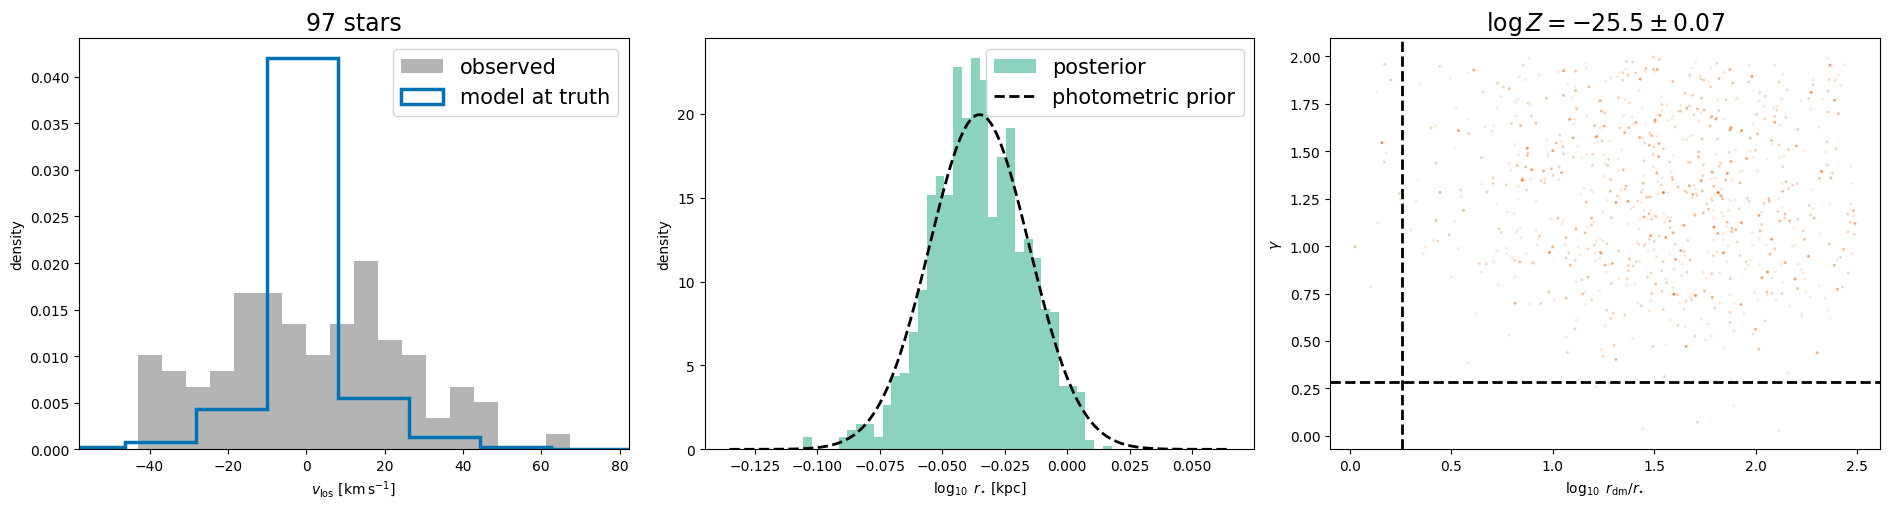

In [14]:
drawn_v = drawn[..., 0].flatten().numpy()

fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))

axes[0].hist(obs.vel[:, 0].numpy(), bins=18, density=True,
             histtype='stepfilled', alpha=0.45, color='0.35',
             label='observed')
axes[0].hist(drawn_v, bins=40, density=True, histtype='step', lw=2.5,
             color='#0072B2', label='model at truth')
axes[0].set_xlim(obs.vel[:, 0].min() - 15, obs.vel[:, 0].max() + 15)
axes[0].set_xlabel(r'$v_{\rm los}\ [{\rm km\,s^{-1}}]$')
axes[0].set_ylabel('density')
axes[0].legend(fontsize=15)
axes[0].set_title(f'{n} stars', fontsize=17)

grid = np.linspace(win_low, win_high, 200)
axes[1].hist(posterior[:, -1], bins=35, density=True,
             histtype='stepfilled', alpha=0.45, color='#009E73',
             label='posterior')
axes[1].plot(grid, truncnorm(
    (win_low - log_rstar) / sigma_dex, (win_high - log_rstar) / sigma_dex,
    loc=log_rstar, scale=sigma_dex).pdf(grid),
    'k--', lw=2, label='photometric prior')
axes[1].set_xlabel(r'$\log_{10}\ r_{\star}\ [{\rm kpc}]$')
axes[1].set_ylabel('density')
axes[1].legend(fontsize=15)

axes[2].scatter(posterior[:, 3], posterior[:, 2], s=4, alpha=0.15,
                color='#D55E00', edgecolors='none')
axes[2].axhline(theta_true[2], color='k', ls='--', lw=2)
axes[2].axvline(theta_true[3], color='k', ls='--', lw=2)
axes[2].set_xlabel(r'$\log_{10}\ r_{\rm dm}/r_{\star}$')
axes[2].set_ylabel(r'$\gamma$')
axes[2].set_title(rf'$\log Z = {log_evidence:.1f}'
                  rf' \pm {log_evidence_err:.2f}$', fontsize=17)

fig.tight_layout()

## Where each step went

| this notebook | `00_nle_frontend.ipynb` |
|---|---|
| §2 build the pipeline by hand | `config.pre_transforms`, applied by `api.train` |
| §3 `compute_field_norm` | inside `api.train`, saved into the checkpoint |
| §4 `prepare_dataloaders` | inside `api.train` |
| §5 `build_flow`, `NLE(...)` | `config.model`, built by `api.train` |
| §6 `pl.Trainer`, `trainer.fit` | `api.train(config)` |
| — | `api.load_model(run_dir)` |
| §7 frozen `StarBatch` | `api.Observation.from_dataset(...)` |
| §8 `galaxy_log_likelihood` | `api.galaxy_log_prob` |
| §8 prior construction | you build it there too: there is no `api.build_prior` |
| §8 `pc.Sampler` | `api.sample_posterior` |
| — | `api.save_posterior` |

The two rows with no left-hand entry are the ones worth noticing. This
notebook never saved anything, so there is nothing to hand anyone and
nothing to load back. `api.train` writes a run directory with the weights,
the normalization and the config in it, and `api.load_model` reads one with
nothing else needed.

That is the difference between an experiment and a result. Use `00` for
anything you intend to keep.